# 03 | Districts and municipalities of Portugal (CAOP)

**Source:** [Direção-Geral do Território – Carta Administrativa Oficial de Portugal (CAOP)](https://www.dgterritorio.gov.pt/atividades/cartografia/cartografia-tematica/caop)

Version 2024.1 was used because it was the most recent version at the time of extraction and it matches the year of the Eurostat data (2024), keeping the datasets consistent in time.

The CAOP is published in four files, each one with its own CRS:

| File | Region | CRS |
|---|---|---|
| `Continente_CAOP2024_1.gpkg` | Mainland Portugal | EPSG:3763 |
| `ArqAcores_GCentral_GOriental_CAOP2024_1.gpkg` | Azores – Central and Eastern groups | EPSG:5015 |
| `ArqAcores_GOcidental_CAOP2024_1.gpkg` | Azores – Western group | EPSG:5014 |
| `ArqMadeira_CAOP2024_1.gpkg` | Madeira | EPSG:5016 |

**Output (layers in `data/processed/layers.gpkg`):** `Districts2024_PT`, `Municipalities2024_PT`, `Districts2024_PT_mainland`, `Municipalities2024_PT_mainland`

## Setup

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable when running from the notebooks/ folder
sys.path.append(str(Path.cwd().parent))

import geopandas as gpd
import numpy as np
import pandas as pd

from src.utils import *

In [2]:
caop_files = {
    "mainland":           ("Continente_CAOP2024_1.gpkg",                   "cont_distritos",        "cont_municipios"),
    "azores_central_east": ("ArqAcores_GCentral_GOriental_CAOP2024_1.gpkg", "raa_cen_ori_distritos", "raa_cen_ori_municipios"),
    "azores_west":        ("ArqAcores_GOcidental_CAOP2024_1.gpkg",         "raa_oci_distritos",     "raa_oci_municipios"),
    "madeira":            ("ArqMadeira_CAOP2024_1.gpkg",                   "ram_distritos",         "ram_municipios"),
}

# List the layers of each file
for region, (file_name, _, _) in caop_files.items():
    print(region, "->", list(gpd.list_layers(RAW_DIR / file_name)["name"]))

mainland -> ['cont_areas_administrativas', 'cont_distritos', 'cont_freguesias', 'cont_municipios', 'cont_nuts1', 'cont_nuts2', 'cont_nuts3', 'cont_trocos', 'layer_styles', 'inf_fonte_troco']
azores_central_east -> ['raa_cen_ori_areas_administrativas', 'raa_cen_ori_distritos', 'raa_cen_ori_freguesias', 'raa_cen_ori_municipios', 'raa_cen_ori_nuts1', 'raa_cen_ori_nuts2', 'raa_cen_ori_nuts3', 'raa_cen_ori_trocos', 'inf_fonte_troco', 'layer_styles']
azores_west -> ['raa_oci_areas_administrativas', 'raa_oci_distritos', 'raa_oci_freguesias', 'raa_oci_municipios', 'raa_oci_nuts1', 'raa_oci_nuts2', 'raa_oci_nuts3', 'raa_oci_trocos', 'inf_fonte_troco', 'layer_styles']
madeira -> ['ram_areas_administrativas', 'ram_distritos', 'ram_freguesias', 'ram_municipios', 'ram_nuts1', 'ram_nuts2', 'ram_nuts3', 'ram_trocos', 'inf_fonte_troco', 'layer_styles']


## Districts

The same steps are applied to each of the four files:
1. Read the districts layer.
2. Add the prefix `PT_` to the district code (e.g. `01` → `PT_01`), so that it matches `DistrictID` in the localities table.
3. Remove unnecessary columns and rename the remaining ones.
4. Reproject to EPSG:4326, so that the four files can be joined.

mainland: 18 districts, CRS 3763
azores_central_east: 7 districts, CRS 5015
azores_west: 2 districts, CRS 5014
madeira: 2 districts, CRS 5016
Total: 29 rows


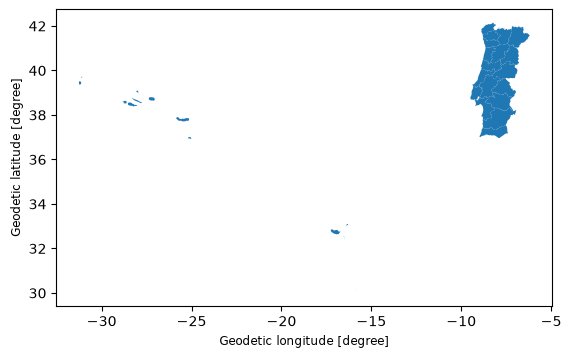

In [3]:
district_tables = {}

for region, (file_name, dist_layer, _) in caop_files.items():
    gdf = gpd.read_file(RAW_DIR / file_name, layer=dist_layer)
    print(f"{region}: {len(gdf)} districts, CRS {gdf.crs.to_epsg()}")

    gdf["dt"] = "PT_" + gdf["dt"]
    gdf = gdf.drop(columns=["nuts1", "n_municipios", "n_freguesias"])
    gdf = gdf.rename(columns={
        "dt": "DistrictID",
        "distrito": "DistrictName",
        "area_ha": "AreaHa",
        "perimetro_km": "PerimeterKm",
    })
    district_tables[region] = gdf.to_crs(4326)

gdf_pt_dist = pd.concat(district_tables.values(), ignore_index=True)
print("Total:", len(gdf_pt_dist), "rows")
gdf_pt_dist.plot();

Validation: one district ID can appear in more than one file (for example, when a district covers islands from different groups). Any repeated ID is listed here:

In [4]:
gdf_pt_dist[gdf_pt_dist.duplicated(subset="DistrictID", keep=False)]

,DistrictID,DistrictName,AreaHa,PerimeterKm,geometry


## Municipalities

mainland: 278 municipalities, CRS 3763
azores_central_east: 16 municipalities, CRS 5015
azores_west: 3 municipalities, CRS 5014
madeira: 11 municipalities, CRS 5016
Total: 308 rows


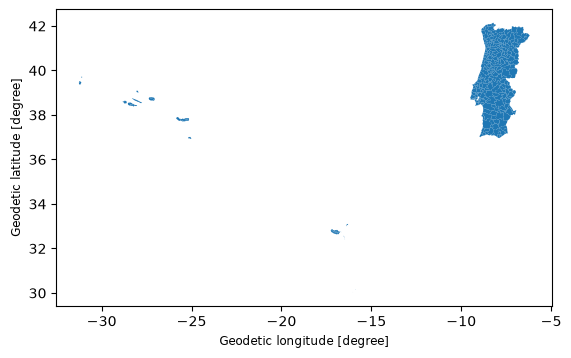

In [5]:
municipality_tables = {}

for region, (file_name, _, mun_layer) in caop_files.items():
    gdf = gpd.read_file(RAW_DIR / file_name, layer=mun_layer)
    print(f"{region}: {len(gdf)} municipalities, CRS {gdf.crs.to_epsg()}")

    gdf["dtmn"] = "PT_" + gdf["dtmn"]
    gdf = gdf.drop(columns=["distrito_ilha", "nuts3", "nuts2", "nuts1", "n_freguesias"])
    gdf = gdf.rename(columns={
        "dtmn": "MunicipalityID",
        "municipio": "MunicipalityName",
        "area_ha": "AreaHa",
        "perimetro_km": "PerimeterKm",
    })
    municipality_tables[region] = gdf.to_crs(4326)

gdf_pt_mun = pd.concat(municipality_tables.values(), ignore_index=True)
print("Total:", len(gdf_pt_mun), "rows")
gdf_pt_mun.plot();

In [6]:
# Municipalities with the same name
gdf_pt_mun[gdf_pt_mun.duplicated(subset="MunicipalityName", keep=False)]

,MunicipalityID,MunicipalityName,AreaHa,PerimeterKm,geometry
106,PT_0806,Lagoa,8825.45,58,"MULTIPOLYGON (((-8.50413 37.10039, -8.50416 37..."
279,PT_4201,Lagoa,4559.32,45,"MULTIPOLYGON (((-25.48391 37.71775, -25.484 37..."


## Centroids, column order and save

In [7]:
dist_columns = ["DistrictID", "DistrictName", "AreaHa", "PerimeterKm", "LonCent", "LatCent", "geometry"]
mun_columns = ["MunicipalityID", "MunicipalityName", "AreaHa", "PerimeterKm", "LonCent", "LatCent", "geometry"]

gdf_pt_dist = add_centroids(gdf_pt_dist)[dist_columns]
gdf_pt_mun = add_centroids(gdf_pt_mun)[mun_columns]

# Mainland only
gdf_pt_dist_mainland = add_centroids(district_tables["mainland"])[dist_columns]
gdf_pt_mun_mainland = add_centroids(municipality_tables["mainland"])[mun_columns]

save_layer(gdf_pt_dist, "Districts2024_PT")
save_layer(gdf_pt_mun, "Municipalities2024_PT")
save_layer(gdf_pt_dist_mainland, "Districts2024_PT_mainland")
save_layer(gdf_pt_mun_mainland, "Municipalities2024_PT_mainland")

Saved layer 'Districts2024_PT' (29 rows)
Saved layer 'Municipalities2024_PT' (308 rows)
Saved layer 'Districts2024_PT_mainland' (18 rows)
Saved layer 'Municipalities2024_PT_mainland' (278 rows)


## Summary
* Read the districts and municipalities layers from the four CAOP 2024.1 files (mainland, Azores Central/Eastern, Azores Western and Madeira).
* Added the prefix `PT_` to the codes, removed unnecessary columns and renamed fields with the same names in all files.
* Reprojected everything to EPSG:4326 and joined the four regions into one table for districts and one for municipalities.
* Added centroids and saved the full Portugal version and the mainland version.